# Game of Life | Nihai deney raporu

Bu notebook **tek başına** açılır ve bütün hazır sonuç grafiklerini çizer. CSV dosyası gerekmez. Orijinal çalışmadan bağımsız bir analiz kopyasıdır, GitHub deposunu değiştirmez.

**Ölçümler:** Son 50 kare üzerinden ortalama canlı hücre oranı (popülasyon) ve iki ardışık kare arasında değişen hücre oranı (aktivite). T=300 (başlangıç kare dahil 300 durum). Sınırlar periyodik. 0.05–0.95 arasında p değerleri taranmıştır.

**Deney aileleri:** Kare 60×60 için M=100 ve M=300, q=1 ve q=0,8. Dikdörtgen L=60/80, Ly=100/200 için M=20 ve q=1. Ek olarak L=60, Ly=100 için M=100 ve q=1.

**Dürüst sınırlama:** Dikdörtgen boyutların tümünü M=100/300 ve q=0,8 ile tarayan çalışmalar bu veri içinde bulunmuyor. M/q ve L/Ly grafikleri farklı deney aileleridir. Farklı p ağlarında zirveler doğrudan hassas bir optimum gibi yorumlanmamalıdır.

q=1 standart B3/S23 Life, q=0,8 ise yalnızca doğum kuralının olasılıksal yapıldığı varyanttır. M tekrar sayısıdır, L ve Ly iki boyutun hücre sayısıdır.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
import zlib, base64

encoded = "eNqlW1uSWzcO/Z+19LhIguBjD8kaXK5JPlI1k6czFe9+ziFwJZKyKXVG1W7b0tUlLggcHDz4x+c/f/jy9t3bd1/evn/77e3Xt19/+fXPf3/6/NMvP3/8z4+ffp7//8cPb5/+9fmn//70+Yt9dvsfPpm/9+mvj7//OX3sb/zj+4+/vZXwIdivGMZv/MHfyl+h1FZjub3GmzH0FFrrWaLgX9GulJRKqvfXeLOlnGoJKi2nHDPfq226H158r8R8ECXykpxb6XH9Woq1Rik5pta05izjzVZSq+n2GlfGHqvmWLtoyHiz8c3eJM8vk67L9DqKpSZ6Ub2vZiKErBI0S+4txDJunEPJk3aqi6WhB6yTRFULHzTiGWcFjUW65OmJkhykSkOoXOouVOwQFFvXpUnBtow3IWKN062zK6v1lorWlEXr2LYYY5tf40JoPU6vdBLLlFV7afcvjMWwb0VTjyF1bXFsTC74p9zW6uM6PBFEbwIFpd7TkCmk2ZLGd1sN8waeZBoaqAF20G7Xm4GXDiUELbAPTaaAkDuM40GokhQ2Lqkp/KCapmS18CGVplfNSlxTUpsJ06LEjNWxb0lqqqahAt/c3LIlla5Je44lyrBxCFPmhYcwPUmfzP4gy3jwUrju7eUPLgVel1qGV3d43BBKYXd3W7Lt1Sr4MmSvML1C4WPIkx7xGgrKOiutnoQyBcGaw+QTpoGaFcKEEpJm7WpS9RK21WKFrgoAQyBggDxDrCLxwZpymUTtB6kuoWLQ28vBIPF9bFylhQQzJnwY7xeq+532ivV6hVFmGaJG4OuEqo5bi6riSaoLo0KcnsOwByrvqQmxCqt2syu4eb4bh2R3UZg3AaTjCdq4Zwx1MfLxbWzyjKd6EMxgHxGj3ZVgYsGuEsy3BMG+2QPDnnvcsD8qQGDICqiFjofrAUNmoQyk4iLoUaihLTxinjHRnatjMaBly3hGRA6+CcMuE3aImxbikcJ/AY6IWUMxvViwqLqA02nnxvekw1PvC2SzJ+2hEQEig6t5Q8qIsZNTV99hgHYQgDQQKrg68oLZYxt0jkztJJTrIixoZr6H+Ao0gPXibjTt8SbspT/QB0BBGA8hmcg2FJP65KIDYjL8YPLvE5APIwmI7HVyPpcAGEHCUmsCPibbtyCxhlkLQ4ZQYWcpg+8kOFUeT6WrRWfblLAQmJNguS+vsQxWX+DP3wVnqVgehg4LDKbUEFauBCi2txEgIzAkd6AY/MTkNx6Wt9dBvI6/+3q1/vhPvw8RI+EPbKNoScAJXB2XV2jT1dvL5N/f/eqbJwnH3b/2Z/uSfIW6IjhPT2exDzKDNMItGyIY/MQkQpBc4MzMgdshiKkESUQ2g1LG4W3vQPRmQ43lIJtxWQ3khyvuYUdxmxbIfnIYNwbwg2m1eP2YV1dJYN0AHtBCuI+FdJUHUl2VfnZ7pZNU9mwJoAokqf5j4A9dkeUgegNMukUqOEqbeYWjQlRQR1CyXIjLI3rV2SGLhdmFSepBLOOyMHqtG6sAk4CTFvhX1AtDMqgG3BqwO36cyzbQRugOmQhCnAyvjhKWDRMjJQt45JNYHuvBwXYuqxWa68RdQYwwig08nJaLHiUAMaDCQD3gtj0AwXIWQWxj2yzqSSxxqbAaIpP9OC0STbg7WQB/FRMLkQt0rfuPSVXhfGDjCSYIHjXYWgKkzwAxpKrlZalMWcN8YV3246t18Hc4GEQCtTfEy6UNCu8/LpUijFQYNLICgKNlSX2WynS1BhE5SOXEFhafV3ROcBSQfxhLFFi5M8gY6iNZy4VC4NHAUqpR/wTaskcgpF0HCimPxJZc/6aB0t23cBPQHRKh5OYOtjrbRrkTWyGLgwJ0YB52XsPmhQE2VyYIPnnhlbkhhb6MxR2+kwnBamHMWj3NxU7rBvgQBvcD1gIb4JaDfuIpZBaqG32TGbFOZuXEFrCtk8vbakhzBUwayk4kXEMs5Co364OxuVIBocAqPFpuoVi+pI81AaDeq9ZutBa6D3epHLGQeCP5hcUjEokrS1gfWZUKR4CfVGQsMmQbuopz0Bm5L5PWWc6TsTutLSA9epfKqRyYKbYEVgHccsxEateWfbhMECansGb4voilTLnLFgzJfg+0TXaKmyMQrt9jnNFZUrAO5lYjYBKuNt6EXU+A5bQT65ELITdBhMqheAZet9SwM5+ffOAklvpGlL49WwRywWaI7TDy5PEYlpybbtudWUPBFQh3fDpTzeqH1TCoz1WhepDLWC4wXWctOHXtCJFgMMBq7vJ4D5CgOa2Yiz0kckliNYgIY26EvHRiqZZztTxzmhNuNaeAIImTGizLRPaBTakFvAI/zMXsWpYFJ2bjDDyxRAePFnhJ0GSULTPN2QqL4EkzfMWT3vrfoJAv804jq745rvfQFtnsXYBwIzFKLK8lsfrf9SdomxOq4VynlczGGJVmgudUFjYH9wXlITyneZm4ZlShPlvGnBEr9Q0SgfNagWkIMkVIHOdlENLDLtdhlfE5jHWJB7YIYTCxYtikWuXmtsaqsfxsDXsS5H3zS3wVYDBcIg86KusyS9HTUOCwjBV8vIpIAwZKpIBwfouF9xsvRCE/ewDxB3jkYoGF8cScHEEYuLks8+y2+brrQ8kZoUJZ+9XCOqi74k36xY6ebfBVoliVbw0CxBNQ8woug6CS+qqixY3kySquoPAVW20R5lNLqPCsHtZFtmz52SK2SsLeTk/iCsMOILVhZgJzsgr5bZmyZI3mWId1PCUMS/2gXubaFGGTpoCEra6et7zis1W8HrNUc0SuOAPCwmxGEaTi8jTrKik/wxETHMp5KEUjqJNutw7ujnTAU9wbXuW1/PEMFn0jkFE8eklksghLRybEftQKv6th1me7Y5E46OoF2es4cMFIf4L+WE5dFloVLU/tDaFVPyzRr041F4FTMV6SwjZ4z6K81RHAEJ/tUv8bIe+d9ZklToJNyUQAmleMMsNjzqyZd/jNEsBCWZ9Jn6x0xck0pZS+urB6RmQGOIgsz55CeujUnRZxvtgebQhhMo2km+ijZdWWpEc8PCzjYTItKki+Col8Ziej85mWVWRB0fTsaa5I2RFL+o1niocE9gLwVwYp09rfG9DkMVR23bsbgTUd7E1ggQs0Nb0XR+UrYVMWD/KHQczM2tieaXXdmrxawLNVPIqq1LvGim8NEnFmAeRjDXmdvi+MymMYlTYnG1Y8zuxjISIg+wLpt5T3zpSWZ+lPVvEAV9pUCLwqy7g7KB+8Fm7TY95U9pSQyWMgRbo9pwy2jOL2WDMrWUHR/8eavdMFgjoZc/E6eUI6CStn/6utZpZWoqzPfPMKpIgxU5nBwh48CSk/EhrcFEFhDaSLObfyzNA8kK7iebwGJSmtRfb9ry7jLY4u6V1v7dkyVxytZbI1x+dGfcBBK6QHb1u2J6x0uT3TmwfSMtuArzOmMworDoHxTd6dL8kaRtuHBZ80T2FUBgB0AUqX0NeIvQXf+GSl/jfi4SGIfvfxuy9z1E0PXQ6JaU62YnVapcLcSQqeqnQnwjGtXdvqERfkWCoz9urfR9K6NHfbxaPnpcpJOutzIJA/9EdZwh29OCSvzcsSCaF87ieYEJABNpBYkavd0KbWHDemys76nLwcxfKOQvPmAKm6SodEhOmYrsL41HYzUWiBEAS4FoDh1TsGZfYqm/MIS9MlHWXx2kuG4leKG8uYFUhR4KylFR+KycH4DGyUzsdNbl7LxFb3PeVGVjjLIidZrHeg8Ox9u4p0hBX4R84FnCn51FDUvf2DvAdwigADUC9WD0fuUHXn7yyJzQZ7FMs2fQTPbTnwxQLeg1CFJKVY1Q2ZsLatC4avJk43IAxmJEw+QGGpP2cZZlw8iWIdA8DR5EG2WQIfxAc9wZppxV7V9JGUVIn/wF+YMa1srI9YMLXPTS0w9En0fpTFGwWMxVsXPmfWbpHmgA56YkYMnYZrvH0hytk0yC6xRm9AcdRnj+FE4aXbfZDLd4vV281/4KKDHXWqPNgTZ0ai/cJRGoOLd2BR9mkdQFjapzrgH8ft8idniX03HCAjrZLJBzMoa7TCj3afT3AuQF5jawBc03uq8MLJeAcAwdxPovQzurcTulf6+D16N9cR5/Lg8Ij22RvtYDOe6CKXJjECniN/clVrasGCegbaz2TgJIPPXQKLfAYmKZlHAQsPuHUzBhOaT1okDqilMdCTGFRNX4bRYOpJT2s5MI+i4tKQi2Bpyl3ETaW5SADe4jKx3I2chw2qUe82g0lzUDRw4yDMA+y0EzJX6LLdSqzuzpx9hCvDa2v1glVWThB62wCeDXNiSQuYUO1OnUOW5hyyzIO0kxSOyVXbpf9RTQasl+ERZuLsFqZrLBdeAbBDpMKm2agL4sdc3DeoGS2ve+A6CnFNIzJJ8iesSHXgpEhpkQ54jb7mlm5Wwi7oAGh4vTHRVke6vYiBT2cxjqbo/VrOxfgigKrKuh6LBXK1tBWeepOyYA9gk0yA1OY8ehL/fsU/wovW4GirHDpwRdO1GIYTnzLUa5KWIWaxXRAuvEv6ANTzgQoOHe87gjTnKMLV7Az9kiCDtTRQBIkggJYFEgFurkpcj1grkMIXS0Xa6EtuJAGafFURPnnKTma9Jrng8nBuzvBCFzYUh1Qw73sd2RRB/K0FElXvnA0U1lUeRb45afFoFP0F2py+AawIIzFsk3WchASW9zGdWhw6R4B0qs3QREOAzniR81nwsykKexhrKS4jmgeJfCSIwwRxnUDi7E8fbcNYOa3knS/NuoHbiEtgX/gwcWLV3IWNax+dl5MAZgiJm7hHY/i9srTFQehqIRAEI13gO6IDmA4CETRi9UckcGEfWEMel5fx55M0Pouk3lbshZN9eGas1Jp6S5CY39aKdUdaQeOKYPM+UkMN5n2wi1249qIwJv2ylhOtSLPHo5Jw8kCEMZr4yIsRrAFGjWN6oGY2kcG+kvpwqn6DDKdvQLGQSm1rsO8BKwThk4wIfVHQ8DCHDpuHWeAGCOWtejWCsWt/PpiDLvPYB8HM2jLysI1rBTaj2ZIC3rFk6MmDXjDGzhjHBaAXvBMueHQLWIlnP0rghFirbOycAx6gnZIYNkHljHkii+vJ6RKefTT/CgTsVoSmQvaxzYJE4ySCS8Cxj5sWoj8k97uDnATW6JpzcnrVqi0aK67DL2Y2ltJwMntvzSFpmWea20ksj03JWDNwSXlkBqkKwNvKJjzfMENh9fiRyLxski1ZL7/YjMEiC91ytpOjN73ChL8F2CCGNbar1ZY5hl149gARPl31STbmpojiqM3iHphK4kmmaONjzBrxwZ1Xe2pAVqcnYa6jSFWn1rt7Fuv7THw7J8gswrESdxO6Zx6XikRljm3a+Eetcwz0LBapkn41JH8Duhngg2My8BIZJ6SAg9OqPbrgplluXicFACk8vOHEIPsgCA/YTOTkuPQ1rRYv0hF4OKeB8YxdqNFPGCFeyu2KyJ4eQxNcwVoeDHEPKRXP2rwohwcYtiFXPQZOpCMZpXOztmfi8FzFRaiB7OzMI7YhuIFKJSsx9bLTFwSU9A1Wkr7JmMnLN4Fk1E3ZzIbbun5w73IRqsARyciYGnMSL+1iOzXeV69W9Ir1VYEcntkauEwE8aJiWZ6XqD37PtFB/POU6f89dkRcb5hBARe3Jgufnee4uGuDWePd/BC+6ZSNpNi10MOV0oVRxSbXYk7RPJCzKWf3Yu/77KVumRJY2NVlB2CtAOPKc2TIY6x6jQvnRO8yHpaeWV+DkMXiBqyp7XGBQDDPuxwF84k3cMd+d/HiWqFvANU4PeNV0cJ0z5XCwmci7wFlZ5Dxcz2X78GG+xOt9Lf84a6PwR3naf8KiGVRlg+DrOCtfFjHeKa+My4rPAE2yostNu98L9NIPjYYlpLxhWYff/zr8++flnH/r8zvK0dAtqH8xhk3dnHL2BdvsQy02doBeAiWHxtCKbhXswxQY3iYkwdA5Rekiu4lvc/hzgrVCEQckgIDohPZ5mHnUt6JGqezeGFhzdrHs1+uaT+R72JN4ucGM4eWWT8ZJMgrtzxoWb0AOIaVAwz8VhUE/5lHFIyBtPpABM+S+BFUBoPtXKXwSQuApJNxWvDJzGj2Ip0ADUQ78jF8I3Z9V739iXQ+vQ+Y1+1gEltA8AFhs7DcBtJ51nlNFEk7FFlQZ9JUrSrAKWsDiR7KQ4nnLJKHsEFEtoVYyyqjgARNuAl2Hvba9IX4Bzuv4P8Q3I9Zsr2xZXRVRJfDcC8IdxXDuh01YV0Ujs5fPKuU/OwFJ4rvKYRfmSrr7r0imMXLwg6l97MgXgNKYapYXGdMG9+P2DXAaLkC/UwsLGlTDoB1i3U9qM0wi9ZHswrvNfor0IEg970DwRPCuOM4IOun4HkqtfS9NB3GIaDObr6an75ekz+LdzuyMtnEDQdi4hwcopt32fDvNvfj7DporzN35ny/YUivIT7AhebyTrz3s6DIYU2izOSzAp14/ip6syDxSOi9B+B4gn1HNBKwosQRcDtEsOTHltCFBWJfEap6RVG7m844E9/IbEFlrI8DffVppsuKz1gIhtjYX4msSFieX6X1h/pnegWvvPcKwrin/UzamJRx7oBnMLxexZx2M5jAc12FZ1iwe9nBPncbBpG1hfyKcvpb+rDG9TRRibR/hKvXU4xapqu3E44+Qx0eRoj3K/UVtzz01v8HhDOhLA=="
df = pd.read_csv(StringIO(zlib.decompress(base64.b64decode(encoded)).decode()))
print('Yüklenen gözlem satırı:', len(df))
print(df.groupby(['study','L','Ly','M','q']).size().to_string())
assert len(df) == 135
assert not df.duplicated(['L','Ly','M','q','p']).any()
assert np.isfinite(df.select_dtypes('number').to_numpy()).all()

Yüklenen gözlem satırı: 135
study       L     Ly     M      q  
L_Ly        60.0  100.0  20.0   1.0    11
                  200.0  20.0   1.0    11
            80.0  100.0  20.0   1.0    11
                  200.0  20.0   1.0    11
L_Ly_extra  60.0  100.0  100.0  1.0    15
M_q         60.0  60.0   100.0  0.8    19
                                1.0    19
                         300.0  0.8    19
                                1.0    19


## M ve q karşılaştırması | L=Ly=60

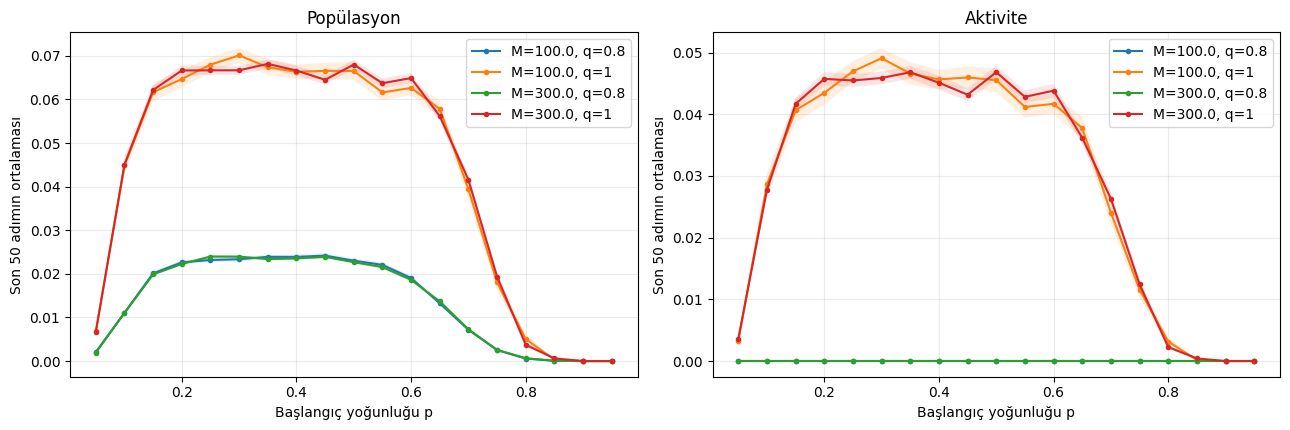

In [2]:
s = df[df.study == 'M_q']
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for (M, q), g in s.groupby(['M','q']):
    g = g.sort_values('p')
    for ax, metric, err in zip(axs, ['population_mean','activity_mean'], ['population_sd','activity_sd']):
        ax.plot(g.p, g[metric], marker='o', markersize=3, label=f'M={M}, q={q:g}')
        ax.fill_between(g.p, g[metric]-g[err]/np.sqrt(M), g[metric]+g[err]/np.sqrt(M), alpha=0.12)
for ax,title in zip(axs,['Popülasyon','Aktivite']):
    ax.set(xlabel='Başlangıç yoğunluğu p', ylabel='Son 50 adımın ortalaması',title=title)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## L ve Ly karşılaştırması | M=20, q=1

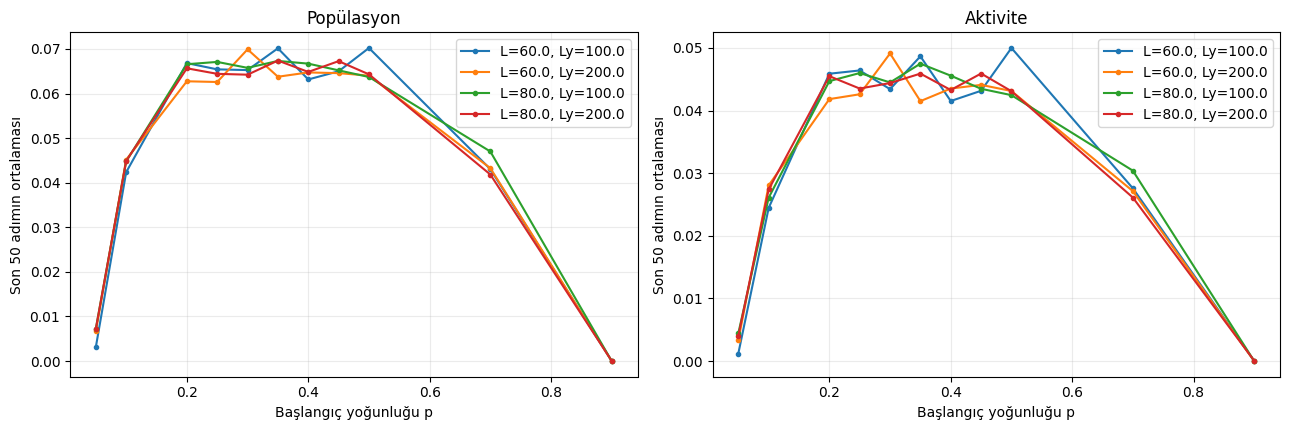

In [3]:
s = df[df.study == 'L_Ly']
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for (L,Ly),g in s.groupby(['L','Ly']):
    g=g.sort_values('p')
    for ax,metric in zip(axs,['population_mean','activity_mean']):
        ax.plot(g.p,g[metric],'o-',markersize=3,label=f'L={L}, Ly={Ly}')
for ax,title in zip(axs,['Popülasyon','Aktivite']):
    ax.set(xlabel='Başlangıç yoğunluğu p',ylabel='Son 50 adımın ortalaması',title=title)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## Maksimumlar ve testler

In [4]:
summary=[]
for (study,L,Ly,M,q),g in df.groupby(['study','L','Ly','M','q']):
    pop=g.loc[g.population_mean.idxmax()]
    act=g.loc[g.activity_mean.idxmax()]
    summary.append([study,L,Ly,M,q,pop.p,pop.population_mean,act.p,act.activity_mean])
peaks=pd.DataFrame(summary,columns=['deney','L','Ly','M','q','pop_tepe_p','pop_tepe','aktivite_tepe_p','aktivite_tepe'])
display(peaks.round(6))
assert (df.population_mean.between(0,1)).all()
assert (df.activity_mean.between(0,1)).all()
assert (df.population_sd >= 0).all() and (df.activity_sd >= 0).all()
print('Veri bütünlüğü kontrolleri geçti.')

,deney,L,Ly,M,q,pop_tepe_p,pop_tepe,aktivite_tepe_p,aktivite_tepe
0,L_Ly,60.0,100.0,20.0,1.0,0.50,0.070213,0.50,0.049989
1,L_Ly,60.0,200.0,20.0,1.0,0.30,0.069908,0.30,0.049115
2,L_Ly,80.0,100.0,20.0,1.0,0.35,0.067307,0.35,0.047482
3,L_Ly,80.0,200.0,20.0,1.0,0.35,0.067390,0.45,0.045910
4,L_Ly_extra,60.0,100.0,100.0,1.0,0.45,0.067167,0.25,0.046209
5,M_q,60.0,60.0,100.0,0.8,0.45,0.024178,0.05,0.000000
6,M_q,60.0,60.0,100.0,1.0,0.30,0.070099,0.30,0.049078
7,M_q,60.0,60.0,300.0,0.8,0.25,0.023971,0.05,0.000000
8,M_q,60.0,60.0,300.0,1.0,0.35,0.068149,0.50,0.046815


Veri bütünlüğü kontrolleri geçti.


## Yeni deneyi yeniden hesaplama (isteğe bağlı)

Aşağıdaki fonksiyon derlenmiş hesaplamayı kullanır. İlk çalıştırma JIT derlemesi nedeniyle yavaş olabilir. **Grafik ve veriler için çalıştırmak zorunda değilsin.** q parametresinde her tekrar için açık bir tohum kullanılır. T=300, son 50 karede ortalama alınır.

Yeni deneylerin sonuçları yukarıdaki doğrulanmış verileri değiştirmez. Kapsamlı ızgaraları M=300 ile tekrar hesaplamak daha uzun sürer.

In [5]:
from numba import njit

@njit
def step(grid, q):
    L, Ly = grid.shape
    other = np.zeros_like(grid)
    for x in range(L):
        for y in range(Ly):
            count = 0
            for dx in (-1, 0, 1):
                for dy in (-1, 0, 1):
                    if dx != 0 or dy != 0:
                        count += int(grid[(x + dx) % L, (y + dy) % Ly])
            if grid[x, y]:
                other[x, y] = count == 2 or count == 3
            elif count == 3:
                other[x, y] = q == 1.0 or np.random.random() < q
    return other

@njit
def one_run(grid, T, window, q, seed):
    np.random.seed(seed)
    pop = 0.0
    activity = 0.0
    for t in range(1, T):
        new = step(grid, q)
        if t >= T - window:
            pop += new.sum() / (grid.size * window)
            activity += np.sum(grid != new) / (grid.size * window)
        grid = new
    return pop, activity

def new_experiment(L=60, Ly=60, M=5, q=1.0, p_values=(0.2, 0.3, 0.4), T=300, window=50):
    results = []
    for p in p_values:
        runs = []
        for j in range(M):
            rng = np.random.default_rng(20261015 + j + int(round(p*100))*10000 + L*1000000 + Ly*100)
            initial = rng.random((L,Ly)) < p
            runs.append(one_run(initial, T, window, q, 91000+j+int(round(p*100))*1000))
        runs=np.array(runs)
        results.append([p,runs[:,0].mean(),runs[:,1].mean()])
    return pd.DataFrame(results,columns=['p','popülasyon','aktivite'])

# Yeni deney örneği:
# display(new_experiment(L=80, Ly=200, M=20, q=0.8))

## Model doğrulama

Aşağıdaki küçük testler, kare/dikdörtgen sınırları ve standart Life kurallarını doğrular. Testlerin çalışması grafikleri yeniden üretmek için gerekli değildir.

In [6]:
empty = np.zeros((7,11), dtype=np.bool_)
assert not step(empty,1.0).any()
block = np.zeros((7,11),dtype=np.bool_)
block[2:4,3:5] = True
assert np.array_equal(step(block,1.0),block)
blinker = np.zeros((7,11),dtype=np.bool_)
blinker[3,3:6] = True
assert np.array_equal(step(step(blinker,1.0),1.0),blinker)
print('Boş ızgara, blok ve osilatör testleri geçti.')

Boş ızgara, blok ve osilatör testleri geçti.
